<a href="https://colab.research.google.com/github/Njeri-Kiarie/Final_Capstone/blob/main/Salama_DistilBERT_Training.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
# Verifying the selected GPU is available
import torch

print("PyTorch version:", torch.__version__)
print("GPU available:", torch.cuda.is_available())

if torch.cuda.is_available():
    print("GPU name:", torch.cuda.get_device_name(0))

PyTorch version: 2.11.0+cu130
GPU available: True
GPU name: Tesla T4


In [2]:
# Uploading the prepared datasets
from google.colab import files

uploaded = files.upload()

Saving dev_chunks.json to dev_chunks.json
Saving test_chunks.json to test_chunks.json
Saving train_chunks.json to train_chunks.json


In [3]:
# Verify the upload
import os

for filename in [
    "train_chunks.json",
    "dev_chunks.json",
    "test_chunks.json"
]:
    print(filename, ":", os.path.exists(filename))

train_chunks.json : True
dev_chunks.json : True
test_chunks.json : True


In [4]:
# Loading the JSON datasets
import pandas as pd

# Load the prepared datasets
train_chunks = pd.read_json("train_chunks.json")
dev_chunks = pd.read_json("dev_chunks.json")
test_chunks_df = pd.read_json("test_chunks.json")

# Check their shapes
print("Training:", train_chunks.shape)
print("Development:", dev_chunks.shape)
print("Testing:", test_chunks_df.shape)

# Check available columns
print("\nColumns:")
print(train_chunks.columns.tolist())

Training: (3255, 6)
Development: (329, 6)
Testing: (510, 6)

Columns:
['narrative_id', 'input_ids', 'gbv_related', 'gbv_type_labels', 'gbv_event_status', 'status_label']


A pytorch dataset allows us to retrieve individual text chunks and their corresponding labels during model training.

In [5]:
# Creating the custom pytorch dataset
import torch
from torch.utils.data import Dataset

class GBVDataset(Dataset):
    def __init__(self, dataframe):
        self.data = dataframe.reset_index(drop=True)

    def __len__(self):
        return len(self.data)

    def __getitem__(self, idx):
        row = self.data.iloc[idx]

        return {
            "input_ids": torch.tensor(
                row["input_ids"], dtype=torch.long
            ),
            "gbv_related": torch.tensor(
                row["gbv_related"], dtype=torch.float32
            ),
            "gbv_type_labels": torch.tensor(
                row["gbv_type_labels"], dtype=torch.float32
            ),
            "status_label": torch.tensor(
                row["status_label"], dtype=torch.long
            ),
            "narrative_id": row["narrative_id"]
        }

In [6]:
# Creating and verifying the pytorch dataset objects
# Create PyTorch datasets
train_dataset = GBVDataset(train_chunks)
dev_dataset = GBVDataset(dev_chunks)
test_dataset = GBVDataset(test_chunks_df)

# Check dataset sizes
print("Training samples:", len(train_dataset))
print("Development samples:", len(dev_dataset))
print("Testing samples:", len(test_dataset))

# Inspect one training sample
sample = train_dataset[0]

print("\nSample input shape:", sample["input_ids"].shape)
print("Binary GBV label:", sample["gbv_related"])
print("GBV type labels:", sample["gbv_type_labels"])
print("Temporal label:", sample["status_label"])
print("Narrative ID:", sample["narrative_id"])

Training samples: 3255
Development samples: 329
Testing samples: 510

Sample input shape: torch.Size([211])
Binary GBV label: tensor(1.)
GBV type labels: tensor([1., 0., 0., 0.])
Temporal label: tensor(1)
Narrative ID: Question 2


All training, development and testing chunks have successfully loaded. The sample contains 211 tokens, the narrative is gbv related, Domestic violence is the only GBV category identified and is ongoing.

Since our narratives have different token lengths, Pytorch cannot combine sequences of different lenghts into a single tensor. We therefore use dynamic padding which pads each batch only to the length of its longest sequence.

In [7]:
# Creating the collate_fn for dynamic padding
from torch.nn.utils.rnn import pad_sequence

def collate_fn(batch):

    # Pad token sequences to the longest sequence in the batch
    input_ids = pad_sequence(
        [item["input_ids"] for item in batch],
        batch_first=True,
        padding_value=0
    )

    # Attention mask: 1 for actual tokens, 0 for padding
    attention_mask = (input_ids != 0).long()

    # Combine classification labels
    gbv_related = torch.stack([
        item["gbv_related"] for item in batch
    ])

    gbv_type_labels = torch.stack([
        item["gbv_type_labels"] for item in batch
    ])

    status_labels = torch.stack([
        item["status_label"] for item in batch
    ])

    narrative_ids = [
        item["narrative_id"] for item in batch
    ]

    return {
        "input_ids": input_ids,
        "attention_mask": attention_mask,
        "gbv_related": gbv_related,
        "gbv_type_labels": gbv_type_labels,
        "status_label": status_labels,
        "narrative_id": narrative_ids
    }

We also use the attention mask to distinguish actual tokens from padding tokens. Hence the model will ignore padding positions when calculating attention.

Dataloaders then organise our data into batches and make it easier to train and evaluate DistilBert

In [8]:
# Creating the dataloaders
from torch.utils.data import DataLoader

batch_size = 8

# Training DataLoader
train_loader = DataLoader(
    train_dataset,
    batch_size=batch_size,
    shuffle=True,
    collate_fn=collate_fn
)

# Development DataLoader
dev_loader = DataLoader(
    dev_dataset,
    batch_size=batch_size,
    shuffle=False,
    collate_fn=collate_fn
)

# Test DataLoader
test_loader = DataLoader(
    test_dataset,
    batch_size=batch_size,
    shuffle=False,
    collate_fn=collate_fn
)

# Check number of batches
print("Training batches:", len(train_loader))
print("Development batches:", len(dev_loader))
print("Testing batches:", len(test_loader))

Training batches: 407
Development batches: 42
Testing batches: 64


We use `shuffle=True` during training since it changes the order in which the model encounters examples helping to reduce order bias.

We use `shuffle=False` for development and testing to keep predictions in a consistent order which makes it easier to aggregate chunk predictions using their `narrative_id`

Before training DistilBert, we verify that the DataLoader correctly combines the tokenized text, attention masks and classification labels

In [9]:
# Inspecting one training batch
# Retrieve one batch from the training DataLoader
batch = next(iter(train_loader))

print("Input IDs shape:", batch["input_ids"].shape)
print("Attention mask shape:", batch["attention_mask"].shape)

print("\nBinary GBV labels shape:", batch["gbv_related"].shape)
print("GBV type labels shape:", batch["gbv_type_labels"].shape)
print("Temporal labels shape:", batch["status_label"].shape)

print("\nNarrative IDs:", batch["narrative_id"])

# Confirm no sequence exceeds DistilBERT's maximum length
print("\nMaximum sequence length:", batch["input_ids"].shape[1])

Input IDs shape: torch.Size([8, 512])
Attention mask shape: torch.Size([8, 512])

Binary GBV labels shape: torch.Size([8])
GBV type labels shape: torch.Size([8, 4])
Temporal labels shape: torch.Size([8])

Narrative IDs: ['Question 1356', 'Question 3477', 'Question 2955', 'Question 2129', 'Question 1417', 'Question 865', 'Question 3257', 'Question 122']

Maximum sequence length: 512


We'll begin with our first task; predicting whether a narrative is GBV-related or not i.e: (1) or (0)

In [10]:
# Loading DistilBert for GBV binary classification
from transformers import AutoModelForSequenceClassification
import torch

# Select GPU
device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

# Load pretrained DistilBERT
binary_model = AutoModelForSequenceClassification.from_pretrained(
    "distilbert-base-uncased",
    num_labels=1
)

# Move model to GPU
binary_model = binary_model.to(device)

print("Device:", device)
print("Model loaded successfully!")

config.json:   0%|          | 0.00/483 [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B /  268MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/100 [00:00<?, ?it/s]

[transformers] DistilBertForSequenceClassification LOAD REPORT from: distilbert-base-uncased
Key                     | Status     | 
------------------------+------------+-
vocab_transform.weight  | UNEXPECTED | 
vocab_layer_norm.weight | UNEXPECTED | 
vocab_transform.bias    | UNEXPECTED | 
vocab_projector.bias    | UNEXPECTED | 
vocab_layer_norm.bias   | UNEXPECTED | 
classifier.bias         | MISSING    | 
pre_classifier.bias     | MISSING    | 
classifier.weight       | MISSING    | 
pre_classifier.weight   | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


Device: cuda
Model loaded successfully!


In [11]:
# Configuring the binary classifier's loss function and optimizer
import torch.nn as nn
from torch.optim import AdamW

# Calculate binary positive class weight from training narratives
positive_count = train_chunks.drop_duplicates("narrative_id")["gbv_related"].sum()
negative_count = train_chunks["narrative_id"].nunique() - positive_count

binary_pos_weight = torch.tensor(
    [negative_count / positive_count],
    dtype=torch.float32,
    device=device
)

# Binary classification loss
binary_loss_fn = nn.BCEWithLogitsLoss(
    pos_weight=binary_pos_weight
)

# Optimizer
binary_optimizer = AdamW(
    binary_model.parameters(),
    lr=2e-5,
    weight_decay=0.01
)

print("Binary positive weight:", binary_pos_weight.item())
print("Learning rate:", binary_optimizer.param_groups[0]["lr"])
print("Loss function:", binary_loss_fn)

Binary positive weight: 1.4017502069473267
Learning rate: 2e-05
Loss function: BCEWithLogitsLoss()


The positive class weight means that misclassifying a GBV-positive example contributes approximately 1.4 times as much positive-class loss as it would without weighting.

In [12]:
# Configuring the training settings
from transformers import get_linear_schedule_with_warmup

# Training configuration
num_epochs = 3

# Total optimizer update steps
total_training_steps = len(train_loader) * num_epochs

# Learning-rate scheduler
binary_scheduler = get_linear_schedule_with_warmup(
    binary_optimizer,
    num_warmup_steps=int(0.1 * total_training_steps),
    num_training_steps=total_training_steps
)

print("Number of epochs:", num_epochs)
print("Training batches per epoch:", len(train_loader))
print("Total training steps:", total_training_steps)
print("Warmup steps:", int(0.1 * total_training_steps))

Number of epochs: 3
Training batches per epoch: 407
Total training steps: 1221
Warmup steps: 122


In [13]:
# Creating the binary classifier training function
from tqdm.auto import tqdm

def train_binary_epoch(model, dataloader, optimizer, scheduler, loss_fn, device):

    model.train()
    total_loss = 0

    progress_bar = tqdm(dataloader, desc="Training")

    for batch in progress_bar:

        # Move inputs and labels to GPU
        input_ids = batch["input_ids"].to(device)
        attention_mask = batch["attention_mask"].to(device)
        labels = batch["gbv_related"].to(device)

        # Clear previous gradients
        optimizer.zero_grad()

        # Forward pass
        outputs = model(
            input_ids=input_ids,
            attention_mask=attention_mask
        )

        # One prediction per chunk
        logits = outputs.logits.squeeze(-1)

        # Calculate binary classification loss
        loss = loss_fn(logits, labels)

        # Backpropagation
        loss.backward()

        # Prevent excessively large gradients
        torch.nn.utils.clip_grad_norm_(
            model.parameters(),
            max_norm=1.0
        )

        # Update model parameters
        optimizer.step()
        scheduler.step()

        # Track training loss
        total_loss += loss.item()

        progress_bar.set_postfix(
            loss=f"{loss.item():.4f}"
        )

    return total_loss / len(dataloader)

The function:
1. Sets DistilBERT to training mode using model.train()
2. Process each batch of 8 text chunks on the GPU.
3. Generate one GBV Classification logit per chunk.
4. Calculate the weighted binary cross-entropy loss.
5. Update the model parameters through backpropagation.

Evaluating how well Salama identifies GBV-related narratives during training.

In [14]:
# Creating the binary classification validation function
import numpy as np
import pandas as pd
import torch

def validate_binary(model, dataloader, loss_fn, device):

    model.eval()
    total_loss = 0
    all_predictions = []

    with torch.no_grad():

        for batch in dataloader:

            input_ids = batch["input_ids"].to(device)
            attention_mask = batch["attention_mask"].to(device)
            labels = batch["gbv_related"].to(device)

            outputs = model(
                input_ids=input_ids,
                attention_mask=attention_mask
            )

            logits = outputs.logits.squeeze(-1)
            loss = loss_fn(logits, labels)

            total_loss += loss.item()

            # Convert logits into probabilities
            probabilities = torch.sigmoid(logits).cpu().numpy()

            for narrative_id, probability, label in zip(
                batch["narrative_id"],
                probabilities,
                labels.cpu().numpy()
            ):
                all_predictions.append({
                    "narrative_id": narrative_id,
                    "probability": float(probability),
                    "actual": int(label)
                })

    # Aggregate chunk predictions into narrative predictions
    predictions_df = pd.DataFrame(all_predictions)

    narrative_predictions = predictions_df.groupby(
        "narrative_id", as_index=False
    ).agg(
        probability=("probability", "mean"),
        actual=("actual", "first")
    )

    # Apply classification threshold
    narrative_predictions["predicted"] = (
        narrative_predictions["probability"] >= 0.5
    ).astype(int)

    y_true = narrative_predictions["actual"].to_numpy()
    y_pred = narrative_predictions["predicted"].to_numpy()

    # Calculate evaluation metrics
    accuracy = np.mean(y_true == y_pred)

    tp = np.sum((y_true == 1) & (y_pred == 1))
    fp = np.sum((y_true == 0) & (y_pred == 1))
    fn = np.sum((y_true == 1) & (y_pred == 0))

    precision = tp / (tp + fp) if (tp + fp) > 0 else 0
    recall = tp / (tp + fn) if (tp + fn) > 0 else 0

    f1 = (
        2 * precision * recall / (precision + recall)
        if (precision + recall) > 0 else 0
    )

    return {
        "loss": total_loss / len(dataloader),
        "accuracy": accuracy,
        "precision": precision,
        "recall": recall,
        "f1": f1
    }

Training the first training experiment for 3 epochs while evaluating the modle on the development dataset after each epoch.

In [15]:
# Training and Validating DistilBERT
# Store training history
binary_history = []

best_f1 = -1.0

for epoch in range(num_epochs):

    print(f"\nEpoch {epoch + 1}/{num_epochs}")
    print("-" * 40)

    # Train for one epoch
    train_loss = train_binary_epoch(
        binary_model,
        train_loader,
        binary_optimizer,
        binary_scheduler,
        binary_loss_fn,
        device
    )

    # Evaluate on development data
    val_metrics = validate_binary(
        binary_model,
        dev_loader,
        binary_loss_fn,
        device
    )

    # Save results
    binary_history.append({
        "epoch": epoch + 1,
        "train_loss": train_loss,
        "val_loss": val_metrics["loss"],
        "accuracy": val_metrics["accuracy"],
        "precision": val_metrics["precision"],
        "recall": val_metrics["recall"],
        "f1": val_metrics["f1"]
    })

    print(f"Training Loss: {train_loss:.4f}")
    print(f"Validation Loss: {val_metrics['loss']:.4f}")
    print(f"Accuracy: {val_metrics['accuracy']:.4f}")
    print(f"Precision: {val_metrics['precision']:.4f}")
    print(f"Recall: {val_metrics['recall']:.4f}")
    print(f"F1 Score: {val_metrics['f1']:.4f}")

    # Save the best model based on validation F1
    if val_metrics["f1"] > best_f1:
        best_f1 = val_metrics["f1"]

        binary_model.save_pretrained(
            "salama_binary_best"
        )

        print("Best model saved!")

# Display training history
binary_results = pd.DataFrame(binary_history)

display(binary_results)


Epoch 1/3
----------------------------------------


Training:   0%|          | 0/407 [00:00<?, ?it/s]

Training Loss: 0.3486
Validation Loss: 0.3795
Accuracy: 0.8951
Precision: 0.8082
Recall: 0.9833
F1 Score: 0.8872


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Best model saved!

Epoch 2/3
----------------------------------------


...

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Best model saved!

Epoch 3/3
----------------------------------------


Training:   0%|          | 0/407 [00:00<?, ?it/s]

Training Loss: 0.0479
Validation Loss: 0.3098
Accuracy: 0.9650
Precision: 0.9365
Recall: 0.9833
F1 Score: 0.9593


,epoch,train_loss,val_loss,accuracy,precision,recall,f1
0,1,0.348552,0.379490,0.895105,0.808219,0.983333,0.887218
1,2,0.099493,0.249167,0.968531,0.944000,0.983333,0.963265
2,3,0.047886,0.309776,0.965035,0.936508,0.983333,0.959350


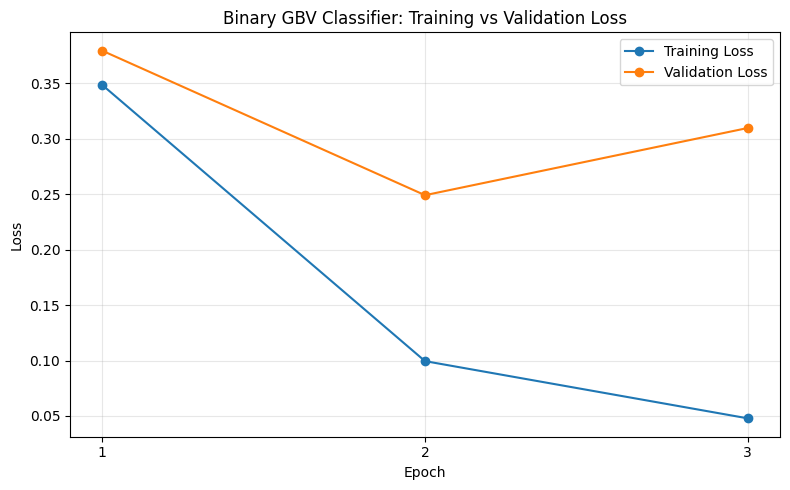

In [17]:
import matplotlib.pyplot as plt

plt.figure(figsize=(8, 5))

plt.plot(
    binary_results["epoch"],
    binary_results["train_loss"],
    marker="o",
    label="Training Loss"
)

plt.plot(
    binary_results["epoch"],
    binary_results["val_loss"],
    marker="o",
    label="Validation Loss"
)

plt.title("Binary GBV Classifier: Training vs Validation Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.xticks(binary_results["epoch"])
plt.legend()
plt.grid(alpha=0.3)

plt.tight_layout()
plt.show()

The DistilBERT binary classifier was fine-tuned for three epochs using a weighted binary cross-entropy loss and the AdamW optimizer.

Training loss decreased consistently across all three epochs, indicating that the model was learning patterns associated with GBV-related narratives.

Validation loss decreased during the first two epochs but increased in the third epoch, suggesting early signs of overfitting.

In [18]:
# Examining the confusion matrix
from transformers import AutoModelForSequenceClassification

# Reload the best model (Epoch 2)
best_binary_model = AutoModelForSequenceClassification.from_pretrained(
    "salama_binary_best"
).to(device)

best_binary_model.eval()

# Get validation predictions
all_predictions = []

with torch.no_grad():
    for batch in dev_loader:
        outputs = best_binary_model(
            input_ids=batch["input_ids"].to(device),
            attention_mask=batch["attention_mask"].to(device)
        )

        probabilities = torch.sigmoid(
            outputs.logits.squeeze(-1)
        ).cpu().numpy()

        for narrative_id, probability, actual in zip(
            batch["narrative_id"],
            probabilities,
            batch["gbv_related"].numpy()
        ):
            all_predictions.append({
                "narrative_id": narrative_id,
                "probability": float(probability),
                "actual": int(actual)
            })

# Aggregate predictions at narrative level
validation_predictions = (
    pd.DataFrame(all_predictions)
    .groupby("narrative_id", as_index=False)
    .agg(
        probability=("probability", "mean"),
        actual=("actual", "first")
    )
)

validation_predictions["predicted"] = (
    validation_predictions["probability"] >= 0.5
).astype(int)

# Calculate confusion matrix counts
tn = ((validation_predictions["actual"] == 0) &
      (validation_predictions["predicted"] == 0)).sum()

fp = ((validation_predictions["actual"] == 0) &
      (validation_predictions["predicted"] == 1)).sum()

fn = ((validation_predictions["actual"] == 1) &
      (validation_predictions["predicted"] == 0)).sum()

tp = ((validation_predictions["actual"] == 1) &
      (validation_predictions["predicted"] == 1)).sum()

print("Confusion Matrix:")
print([[tn, fp], [fn, tp]])

print("\nTrue Negatives:", tn)
print("False Positives:", fp)
print("False Negatives:", fn)
print("True Positives:", tp)

Loading weights:   0%|          | 0/104 [00:00<?, ?it/s]

Confusion Matrix:
[[np.int64(159), np.int64(7)], [np.int64(2), np.int64(118)]]

True Negatives: 159
False Positives: 7
False Negatives: 2
True Positives: 118


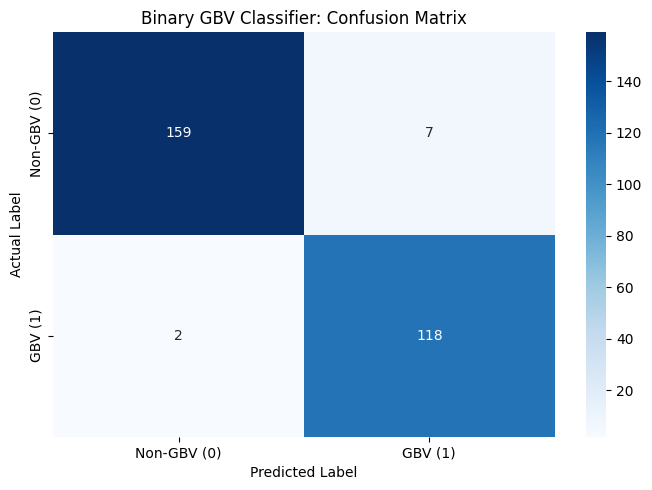

In [19]:
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np

cm = np.array([
    [159, 7],
    [2, 118]
])

plt.figure(figsize=(7, 5))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["Non-GBV (0)", "GBV (1)"],
    yticklabels=["Non-GBV (0)", "GBV (1)"]
)

plt.title("Binary GBV Classifier: Confusion Matrix")
plt.xlabel("Predicted Label")
plt.ylabel("Actual Label")

plt.tight_layout()
plt.show()

In [20]:
# Examining the misclassified narratives
# Extract incorrectly classified narratives
misclassified = validation_predictions[
    validation_predictions["actual"] !=
    validation_predictions["predicted"]
].copy()

# Identify the error type
misclassified["error_type"] = misclassified.apply(
    lambda row: "False Negative"
    if row["actual"] == 1
    else "False Positive",
    axis=1
)

display(
    misclassified[
        ["narrative_id", "actual", "predicted",
         "probability", "error_type"]
    ].sort_values("error_type")
)

,narrative_id,actual,predicted,probability,error_type
110,Question 233,1,0,0.008730,False Negative
140,Question 288,1,0,0.075337,False Negative
6,Question 104,0,1,0.949495,False Positive
11,Question 109,0,1,0.997389,False Positive
15,Question 112,0,1,0.997818,False Positive
23,Question 120,0,1,0.997688,False Positive
103,Question 226,0,1,0.998094,False Positive
184,Question 345,0,1,0.901714,False Positive
245,Question 420,0,1,0.818550,False Positive


In [21]:
# Investigating the original narratives
from transformers import AutoTokenizer

tokenizer = AutoTokenizer.from_pretrained(
    "distilbert-base-uncased"
)

# Examine the two false negatives
false_negative_ids = ["Question 233", "Question 288"]

for narrative_id in false_negative_ids:

    chunks = dev_chunks[
        dev_chunks["narrative_id"] == narrative_id
    ]

    print(f"\n{'=' * 60}")
    print("Narrative:", narrative_id)
    print("Number of chunks:", len(chunks))
    print("GBV type labels:", chunks.iloc[0]["gbv_type_labels"])
    print("Temporal status:", chunks.iloc[0]["gbv_event_status"])

    for i, token_ids in enumerate(chunks["input_ids"], start=1):
        text = tokenizer.decode(
            token_ids,
            skip_special_tokens=True
        )

        print(f"\nChunk {i}:")
        print(text)

tokenizer_config.json:   0%|          | 0.00/48.0 [00:00<?, ?B/s]

vocab.txt:   0%|          | 0.00/232k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/466k [00:00<?, ?B/s]


Narrative: Question 233
Number of chunks: 1
GBV type labels: [0, 1, 0, 0]
Temporal status: past

Chunk 1:
breaking a 5 month streak of no self harm and 2 month streak of no suicidal thoughts. hi its 1 : 18am currently and i really really want to kill myself. i feel like the biggest failure of a human to ever exist. among other things, i was recently diagnosed with adhd and i feel like that was the nail in the coffin. i know this is bleak and unhealthy but i feel like a reject from the human manufacturing factory, like i was built to become a failure and there ’ s nothing i can do to change it. ive tried so so hard to but at the end of the day im still a piece of shit inconsiderate failure of a child / partner / friend. i thought i was getting better i really did. this year has been the worst year ever but despite my grandma dying, getting sexually assaulted by a close friend, getting diagnosed with adhd, and getting fired from my job im still here. i was on track to get better. i was 

In [22]:
# Examining the seven false positives
false_positive_ids = misclassified.loc[
    misclassified["error_type"] == "False Positive",
    "narrative_id"
].tolist()

for narrative_id in false_positive_ids:

    chunks = dev_chunks[
        dev_chunks["narrative_id"] == narrative_id
    ]

    print(f"\n{'=' * 60}")
    print("Narrative:", narrative_id)
    print("GBV type labels:", chunks.iloc[0]["gbv_type_labels"])
    print("Temporal status:", chunks.iloc[0]["gbv_event_status"])

    for i, token_ids in enumerate(chunks["input_ids"], start=1):
        print(f"\nChunk {i}:")
        print(tokenizer.decode(token_ids, skip_special_tokens=True))


Narrative: Question 104
GBV type labels: [0, 0, 0, 0]
Temporal status: not_applicable

Chunk 1:
i don ’ t get what the point of living is if i don ’ t enjoy anything. don ’ t even have any drugs and haven ’ t seen friends in a while. haven ’ t eaten in days cause i just don ’ t get out of bed and tell my family i ’ m not hungry when they ask. i don ’ t accomplish anything and i ’ ll never accomplish anything, haven ’ t been in a relationship in 3 years, i ’ m a useless fucking felon. just why suffer? don ’ t get the point. my life has always just been fucked up from all my mental illness and fucked circumstances, if i was never born i wouldn ’ t have had to experience all this pain. * * leave a row blank if that crisis type is not present. * *

Narrative: Question 109
GBV type labels: [0, 0, 0, 0]
Temporal status: not_applicable

Chunk 1:
who else feels like they ' re only still living to spare the feelings of their family members? there ' s nothing in my life worth living for anymore